# CNN base: red desde cero y búsqueda de configuraciones

Clasificador de huevos sobre los recortes de `data/crops/` (3 clases: ascaris, hookworm, trichuris). Se busca una red pequeña entrenada desde cero, sin pesos preentrenados. Sirve para medir como distintas formas de abordar el problema presentan resultados distintos. Para ello se parte de la experimentación para lograr una red competitiva.

## Cómo funciona este notebook

1. Define 10 configuraciones. Cada una cambia una sola cosa respecto a la `base`.
2. Entrena cada una **25 épocas**, con la misma semilla, una tras otra, y guarda todo en `dl/outputs/cnn/<nombre>/` (configuración, curvas, mejor peso). Se entrena solo con 25 para ver como evoluciona y para ahorrar recursos.
3. Si una configuración ya terminó, se reutiliza y no se vuelve a entrenar.
4. Compara las curvas y las métricas y elige la configuración que será la base para las corridas finalistas.

## Reglas

- Mismo split que todo el proyecto. Solo se leen `train` y `valid`. `test` nunca se carga en este notebook.
- Todo se decide con `valid`. Con 1 semilla por configuración, una diferencia pequeña puede ser ruido: por eso más abajo se calcula un intervalo de ruido a partir de la `base`.

In [1]:
import json
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageOps
from sklearn.metrics import confusion_matrix, f1_score
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms as T

## 1. Parámetros fijos

In [ ]:
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'CLAUDE.md').is_file())
CROPS_CSV = ROOT / 'data/crops/crops.csv'
OUT_DIR = ROOT / 'dl/outputs/cnn'
CLASSES = ['ascaris', 'hookworm', 'trichuris']

SEED = 42
EPOCHS = 25
PATIENCE = 10            # Para sino ve algun tipo de cambio
BATCH = 32               # De a cuantas imagenes se van a entrenar
IMG_SIZE = 224           # Tamaño del recorte de la imagen (224x224)
WEIGHT_DECAY = 1e-2      # Que tanto se van a enconger los pesos de la red
LABEL_SMOOTHING = 0.1    # Regularización para que la red no se sobreentrene en los datos de entrenamiento
MIXUP_ALPHA = 0.4        # Mezcla las imagenes para no volverla rigida
TRAIN_EVAL_SIZE = 500    # Cantidad de imágenes de entrenamiento (sin aumento) para dibujar las curvas de entrenamiento
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
NUM_WORKERS = min(8, len(os.sched_getaffinity(0)))
print('device:', torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'cpu', '| workers:', NUM_WORKERS)
assert CROPS_CSV.is_file(), f'missing {CROPS_CSV}: run data_prep/src/crop_eggs.py first'

device: cpu | workers: 8


## 2. Las 10 configuraciones

Cada fila cambia **un solo factor** de la `base` (el nombre dice cuál):

| Factor | Configuraciones | Qué pregunta responde |
|---|---|---|
| Aumentos | `aug_low`, `aug_high`, `aug_mixup` | ¿Cuánta degradación de color, desenfoque y ruido ayuda? ¿Ayuda mezclar imágenes (MixUp)? |
| Profundidad | `blocks_3`, `blocks_5` | ¿Sobra o falta capacidad? |
| Conexiones residuales | `residual` | ¿Ayudan a entrenar mejor? |
| Learning rate | `lr_3e-4`, `lr_3e-3` | ¿Qué tan rápido conviene aprender? |
| Dropout | `dropout_0.5` | ¿Más regularización reduce el sobreajuste? |

Los aumentos 90° y los volteos se aplican siempre (un huevo no tiene arriba ni abajo). Los niveles `low`, `mid` y `high` suben la fuerza del color, la probabilidad de desenfoque y la del ruido.

In [ ]:
BASE = dict(blocks=4, width=32, residual=False, dropout=0.3, lr=1e-3, aug='mid', mixup=False)

CHANGES = {
    'base': {},
    'aug_low': dict(aug='low'),
    'aug_high': dict(aug='high'),
    'aug_mixup': dict(mixup=True),
    'blocks_3': dict(blocks=3),
    'blocks_5': dict(blocks=5),
    'residual': dict(residual=True),
    'lr_3e-4': dict(lr=3e-4),
    'lr_3e-3': dict(lr=3e-3),
    'dropout_0.5': dict(dropout=0.5),
}
CONFIGS = {name: {**BASE, **changes} for name, changes in CHANGES.items()}

AUG = {
    'low': dict(color=0.1, blur=0.0, noise=0.0),
    'mid': dict(color=0.3, blur=0.3, noise=0.3),
    'high': dict(color=0.5, blur=0.5, noise=0.5),
}
pd.DataFrame(CONFIGS).T

,blocks,width,residual,dropout,lr,aug,mixup
base,4,32,False,0.3,0.001,mid,False
aug_low,4,32,False,0.3,0.001,low,False
aug_high,4,32,False,0.3,0.001,high,False
aug_mixup,4,32,False,0.3,0.001,mid,True
blocks_3,3,32,False,0.3,0.001,mid,False
blocks_5,5,32,False,0.3,0.001,mid,False
residual,4,32,True,0.3,0.001,mid,False
lr_3e-4,4,32,False,0.3,0.0003,mid,False
lr_3e-3,4,32,False,0.3,0.003,mid,False
dropout_0.5,4,32,False,0.5,0.001,mid,False


## 3. Datos

Cada recorte se rellena a cuadrado con su color medio, nunca se estira: la forma del huevo es lo que distingue la especie, y se lleva a 224 × 224. Los aumentos solo se aplican a `train`.

In [ ]:
def pad_to_square(img):
    side = max(img.size)
    fill = tuple(int(c) for c in np.asarray(img).reshape(-1, 3).mean(axis=0))
    return ImageOps.pad(img, (side, side), color=fill, centering=(0.5, 0.5))


def dihedral(img):
    img = img.rotate(90 * random.randrange(4))
    return ImageOps.mirror(img) if random.random() < 0.5 else img


class AddNoise:
    def __init__(self, p, max_std=0.05):
        self.p, self.max_std = p, max_std

    def __call__(self, x):
        if random.random() < self.p:
            x = x + torch.randn_like(x) * random.uniform(0.01, self.max_std)
        return x.clamp(0, 1)


def make_transform(aug=None):
    steps = [T.Resize((IMG_SIZE, IMG_SIZE), interpolation=T.InterpolationMode.BICUBIC)]
    if aug is not None:
        a = AUG[aug]
        steps += [
            T.Lambda(dihedral),
            T.ColorJitter(a['color'], a['color'], a['color'], a['color'] * 0.1),
            T.RandomApply([T.GaussianBlur(5, sigma=(0.5, 2.0))], p=a['blur']),
        ]
    steps.append(T.ToTensor())
    if aug is not None:
        steps.append(AddNoise(a['noise']))
    steps.append(T.Normalize(MEAN, STD))
    return T.Compose(steps)


class Crops(Dataset):
    def __init__(self, images, labels, aug=None):
        self.images, self.labels, self.tf = images, labels, make_transform(aug)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return self.tf(self.images[i]), self.labels[i]


df = pd.read_csv(CROPS_CSV)
df = df[df['split'].isin(['train', 'valid'])] 
assert 'test' not in set(df['split'])


def load(split):
    part = df[df['split'] == split]
    images = [pad_to_square(Image.open(ROOT / p).convert('RGB')) for p in part['crop_path']]
    return images, [CLASSES.index(label) for label in part['label']]


train_imgs, train_y = load('train')
valid_imgs, valid_y = load('valid')
df.groupby(['split', 'label']).size().unstack()

label,ascaris,hookworm,trichuris
split,,,
train,636,650,638
valid,136,140,137


In [ ]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def make_loader(images, labels, aug, shuffle):
    g = torch.Generator()
    g.manual_seed(SEED)
    return DataLoader(Crops(images, labels, aug), batch_size=BATCH, shuffle=shuffle, drop_last=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=(DEVICE == 'cuda'),
                      persistent_workers=NUM_WORKERS > 0, generator=g)

subset = np.random.RandomState(0).choice(len(train_y), TRAIN_EVAL_SIZE, replace=False)
train_eval_loader = make_loader([train_imgs[i] for i in subset], [train_y[i] for i in subset], None, shuffle=False)
valid_loader = make_loader(valid_imgs, valid_y, None, shuffle=False)

## 4. La red

Cada **bloque** son dos convoluciones 3×3 con `BatchNorm` (normaliza las activaciones de cada canal dentro de la red, haciendo que las distribuciones de la entrada no cambien bruscamente) y `ReLU` (deja pasar los valores positivos para continuar con la no linealidad de la red convolucional), y un `MaxPool` (reduce resolución, quedandose solo con el valor maximo en un area en este caso 2x2 que reduce la imagen a la mitad). 

El número de canales se duplica en cada bloque (32, 64, 128, 256 en la `base`). Al final, un promedio global (`AdaptiveAvgPool`), `Dropout` y una capa lineal con 3 salidas.

Con `residual=True` cada bloque suma además un atajo (convolución 1×1) de su entrada a su salida, permitiendo tener esos valores iniciales para crear una corelacion. Las demás configuraciones cambian la profundidad (`blocks`) o el `dropout`.

In [6]:
class Block(nn.Module):
    def __init__(self, cin, cout, residual):
        super().__init__()
        self.conv1 = nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))
        self.conv2 = nn.Sequential(nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout))
        self.skip = nn.Sequential(nn.Conv2d(cin, cout, 1, bias=False), nn.BatchNorm2d(cout)) if residual else None
        self.pool = nn.MaxPool2d(2)

    def forward(self, x):
        out = self.conv2(self.conv1(x))
        if self.skip is not None:
            out = out + self.skip(x)
        return self.pool(F.relu(out))


class CNN(nn.Module):
    def __init__(self, blocks, width, residual, dropout, n_classes=3):
        super().__init__()
        chans = [3] + [width * 2 ** i for i in range(blocks)]
        self.features = nn.Sequential(*[Block(chans[i], chans[i + 1], residual) for i in range(blocks)])
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(chans[-1], n_classes))

    def forward(self, x):
        return self.head(self.features(x))


def build_model(cfg):
    return CNN(cfg['blocks'], cfg['width'], cfg['residual'], cfg['dropout'])


print(build_model(CONFIGS['base']))
pd.Series({name: sum(p.numel() for p in build_model(cfg).parameters()) for name, cfg in CONFIGS.items()}, name='parameters')

CNN(
  (features): Sequential(
    (0): Block(
      (conv1): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
      (conv2): Sequential(
        (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Block(
      (conv1): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
      (conv2): Sequential(
        (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1),

base           1173987
aug_low        1173987
aug_high       1173987
aug_mixup      1173987
blocks_3        287843
blocks_5       4715747
residual       1218051
lr_3e-4        1173987
lr_3e-3        1173987
dropout_0.5    1173987
Name: parameters, dtype: int64

Aqui podemos identificar la cantidad de parametros de la red en cada configuracion, aquellas configuraciones que no camnbian parte de la red presentan los mismos parametros, sin embargo blocks_3, blocks_5 y residual que es quien mas genera cambios. 

## 5. Entrenamiento

El entrenamiento se realiza con los datos fijados anteriormente y un cambio para cada configuraciónm asi mismo utilizamos:  **AdamW** como optimizador, el cual adapta el tamaño del paso de acuerdo a cada peso, aqui enta el weight decay,  programación **coseno** para el learning rate que baja a ~0 en la última época, y parada temprana por **F1 macro en `valid`** si entre las 3 clases no se supera la anterior por 10 epocas. Se guarda el peso de la mejor época.

Si el job se corta a mitad de una configuración, esa se vuelve a entrenar desde cero al relanzar; las ya terminadas se reutilizan.

In [7]:
def evaluate(model, loader):
    model.eval()
    total, preds, ys = 0.0, [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            out = model(x)
            total += F.cross_entropy(out, y, reduction='sum').item()   # plain loss, no smoothing
            preds.append(out.argmax(1).cpu())
            ys.append(y.cpu())
    preds, ys = torch.cat(preds).numpy(), torch.cat(ys).numpy()
    return total / len(ys), preds, ys


def train_run(name, cfg):
    run_dir = OUT_DIR / name
    if (run_dir / 'done.json').is_file():
        print(f'{name}: already trained, reused')
        return
    run_dir.mkdir(parents=True, exist_ok=True)
    (run_dir / 'config.json').write_text(json.dumps(cfg, indent=2))

    set_seed(SEED)
    model = build_model(cfg).to(DEVICE)
    n_params = sum(p.numel() for p in model.parameters())
    opt = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    crit = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    train_loader = make_loader(train_imgs, train_y, cfg['aug'], shuffle=True)

    history, best_f1, best_epoch, start = [], -1.0, 0, time.time()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            if cfg['mixup']:
                lam = float(np.random.beta(MIXUP_ALPHA, MIXUP_ALPHA))
                perm = torch.randperm(len(x), device=DEVICE)
                out = model(lam * x + (1 - lam) * x[perm])
                loss = lam * crit(out, y) + (1 - lam) * crit(out, y[perm])
            else:
                loss = crit(model(x), y)
            opt.zero_grad()
            loss.backward()
            opt.step()
        sched.step()

        tr_loss, tr_pred, tr_true = evaluate(model, train_eval_loader)
        va_loss, va_pred, va_true = evaluate(model, valid_loader)
        row = dict(epoch=epoch, train_loss=tr_loss, val_loss=va_loss,
                   train_f1=f1_score(tr_true, tr_pred, average='macro'),
                   val_f1=f1_score(va_true, va_pred, average='macro'))
        history.append(row)
        if row['val_f1'] > best_f1:
            best_f1, best_epoch = row['val_f1'], epoch
            torch.save(model.state_dict(), run_dir / 'best.pt')
        val_f1 = row['val_f1']
        minutes = (time.time() - start) / 60
        print(f'{name} | epoch {epoch:2d}/{EPOCHS} | val F1 {val_f1:.4f} (best {best_f1:.4f}) | {minutes:.1f} min')
        if epoch - best_epoch >= PATIENCE:
            print(f'{name}: early stop at epoch {epoch}')
            break

    pd.DataFrame(history).to_csv(run_dir / 'history.csv', index=False)
    summary = dict(best_epoch=best_epoch, best_val_f1=best_f1, n_params=n_params, epochs_run=len(history),
                   minutes=round((time.time() - start) / 60, 2), device=DEVICE)
    (run_dir / 'done.json').write_text(json.dumps(summary, indent=2))

In [8]:
for name, cfg in CONFIGS.items():
    train_run(name, cfg)

base | epoch  1/25 | val F1 0.4156 (best 0.4156) | 1.0 min


base | epoch  2/25 | val F1 0.4116 (best 0.4156) | 2.1 min


base | epoch  3/25 | val F1 0.4030 (best 0.4156) | 3.1 min


base | epoch  4/25 | val F1 0.3703 (best 0.4156) | 4.1 min


base | epoch  5/25 | val F1 0.3875 (best 0.4156) | 5.1 min


base | epoch  6/25 | val F1 0.3988 (best 0.4156) | 6.2 min


... (1,113 outputs left out)

OSError: [Errno 16] Device or resource busy: '/scratch/scar-test/job_29458/pymp-zelbpz61'


OSError: [Errno 16] Device or resource busy: '/scratch/scar-test/job_29458/pymp-rfpcc0b_'


OSError: [Errno 16] Device or resource busy: '/scratch/scar-test/job_29458/pymp-c3hdkjwa'


dropout_0.5 | epoch 25/25 | val F1 0.5610 (best 0.5637) | 24.2 min


## 6. Resultados

Para cada configuración, los valores de su **mejor época** (la de mayor F1 macro en `valid`). `gap` es F1 de train menos F1 de valid: si es grande, la red está memorizando.

In [9]:
rows, histories = [], {}
for name in CONFIGS:
    done = json.loads((OUT_DIR / name / 'done.json').read_text())
    histories[name] = pd.read_csv(OUT_DIR / name / 'history.csv')
    best = histories[name].iloc[done['best_epoch'] - 1]
    rows.append({'run': name, 'parameters': done['n_params'], 'best_epoch': done['best_epoch'],
                 'epochs_run': done['epochs_run'], 'train_f1': best['train_f1'], 'val_f1': best['val_f1'],
                 'gap': best['train_f1'] - best['val_f1'], 'minutes': done['minutes']})
results = pd.DataFrame(rows).set_index('run')
results.sort_values('val_f1', ascending=False).round(4)

,parameters,best_epoch,epochs_run,train_f1,val_f1,gap,minutes
run,,,,,,,
lr_3e-4,1173987,20,25,0.8894,0.9027,-0.0133,24.36
blocks_5,4715747,25,25,0.9062,0.8815,0.0247,26.73
aug_low,1173987,22,25,0.8441,0.8402,0.0038,25.10
residual,1218051,23,25,0.7765,0.8027,-0.0262,30.76
aug_mixup,1173987,23,25,0.5834,0.6863,-0.1029,25.95
base,1173987,25,25,0.6185,0.6432,-0.0247,25.63
dropout_0.5,1173987,24,25,0.5311,0.5637,-0.0326,24.25
aug_high,1173987,22,25,0.5154,0.5271,-0.0117,25.92
blocks_3,287843,25,25,0.5108,0.5233,-0.0126,23.04


**1. La red está subentrenada, no sobreajustada.** La configuración `base` obtiene F1 de 0,619 en train y 0,643 en valid: las dos cifras son bajas y casi iguales. Ninguna configuración muestra una brecha grande: la mayor es `blocks_5`, con +0,025, y la mayoría de los valores son negativos o cercanos a cero. Además, `base`, `blocks_3` y `blocks_5` alcanzan su mejor época en la última (la 25), y otras seis entre la 22 y la 24: la mayoría seguía mejorando al terminar. Con `gap` negativo no hay que concluir que a la red le va mejor en `valid`: con una red que aprende poco, la diferencia es ruido, y `train_f1` se calcula con solo 500 recortes.

**2. Lo que ayudó es lo que facilita la optimización.**
- **Learning rate más bajo:** `lr_3e-4` (F1 0,903) frente a `base` con `lr` 1e-3 (0,643). Es el factor que más pesó. Con `lr` 3e-3 el resultado empeora (0,462) y el entrenamiento se detuvo en la época 18, con su mejor época en la 8.
- **Más profundidad:** 3, 4 y 5 bloques dan 0,523, 0,643 y 0,882. La tendencia es monótona.
- **Menos aumentos:** `aug_low` (0,840), `aug` intermedio (0,643) y `aug_high` (0,527).
- **Conexiones residuales:** `residual` (0,803) frente a `base` (0,643).

**3. Lo que no ayudó es lo que regulariza.** `dropout_0.5` (0,564) empeora frente a `base`, algo esperable en una red que todavía no aprende lo suficiente. MixUp (0,686) queda dentro del intervalo de ruido de la `base` (calculado más abajo), así que no se distingue de ella.


### ¿Cuánto es ruido?

Cada configuración se entrenó con **una sola semilla**. Para saber qué diferencias importan, se calcula un intervalo de 95 % para el F1 de la `base` remuestreando los recortes de `valid` (*bootstrap*, 1000 veces). Una configuración cuyo F1 cae dentro de esa franja **no se distingue de la base**.

base: val F1 0.6432, 95% interval [0.5995, 0.6872]


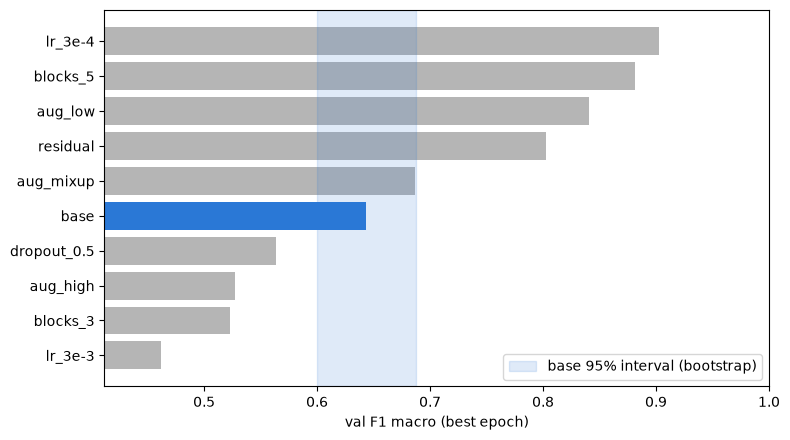

In [10]:
def load_model(name):
    model = build_model(CONFIGS[name]).to(DEVICE)
    model.load_state_dict(torch.load(OUT_DIR / name / 'best.pt', map_location=DEVICE))
    return model


_, base_pred, base_true = evaluate(load_model('base'), valid_loader)
rng = np.random.default_rng(SEED)
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(base_true), len(base_true))
    boot.append(f1_score(base_true[idx], base_pred[idx], average='macro'))
low, high = np.percentile(boot, [2.5, 97.5])
print(f'base: val F1 {results.loc["base", "val_f1"]:.4f}, 95% interval [{low:.4f}, {high:.4f}]')

order = results['val_f1'].sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(order.index, order.values, color=['#2a78d6' if n == 'base' else '#b5b5b5' for n in order.index])
ax.axvspan(low, high, color='#2a78d6', alpha=0.15, label='base 95% interval (bootstrap)')
ax.set(xlim=(max(0, order.min() - 0.05), 1.0), xlabel='val F1 macro (best epoch)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

### Curvas

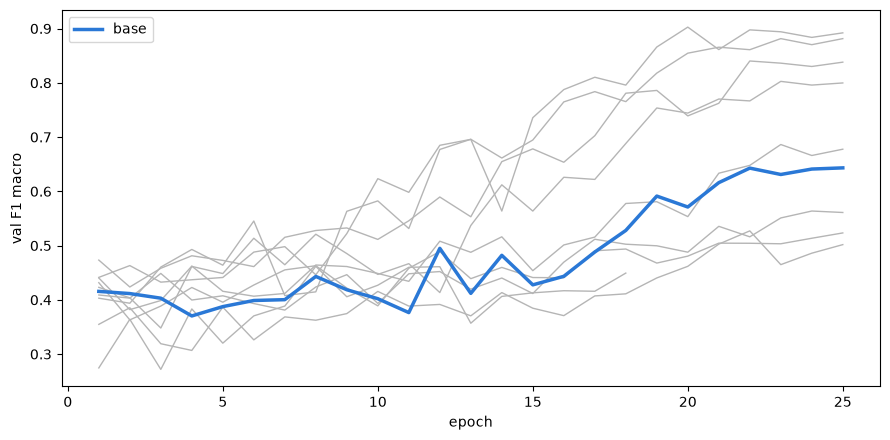

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for name, h in histories.items():
    is_base = name == 'base'
    ax.plot(h['epoch'], h['val_f1'], color='#2a78d6' if is_base else '#b5b5b5',
            lw=2.5 if is_base else 1, label=name if is_base else None, zorder=3 if is_base else 2)
ax.set(xlabel='epoch', ylabel='val F1 macro')
ax.legend()
plt.tight_layout()
plt.show()

**Curvas de validación.** En azul `base`; en gris, las demás configuraciones. Durante las primeras ~10 épocas todas oscilan entre 0,3 y 0,5 (cerca del azar para 3 clases); luego se separan. Ninguna curva se aplana en la época 25, es decir, la mayoría seguía mejorando al terminar (subentrenamiento), y la que termina en la época 18 es `lr_3e-3`, detenida por early stopping.


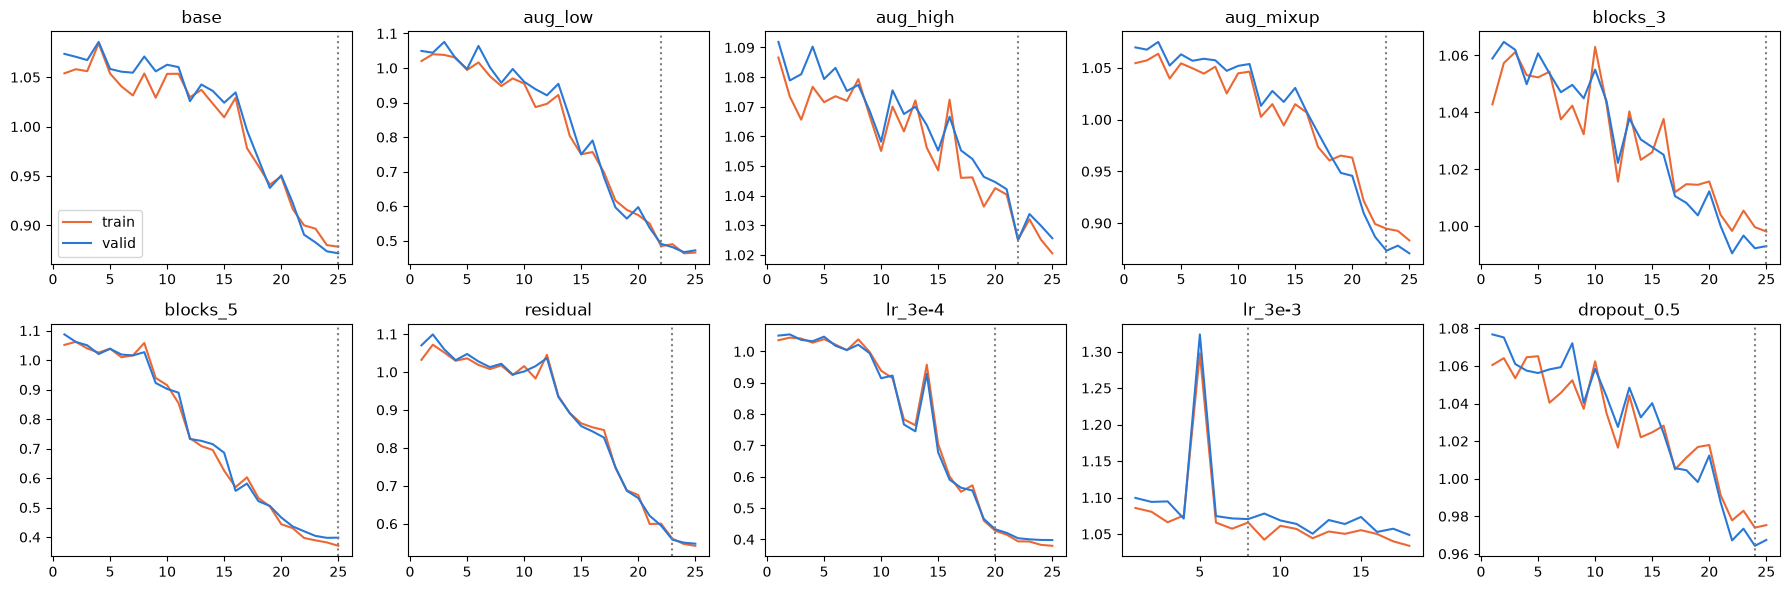

In [12]:
fig, axes = plt.subplots(2, 5, figsize=(18, 6))
for ax, (name, h) in zip(axes.ravel(), histories.items()):
    ax.plot(h['epoch'], h['train_loss'], color='#eb6834', label='train')
    ax.plot(h['epoch'], h['val_loss'], color='#2a78d6', label='valid')
    ax.axvline(results.loc[name, 'best_epoch'], color='gray', ls=':')
    ax.set_title(name)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

**Curvas de pérdida (train en naranja, valid en azul; la línea punteada marca la mejor época).** La pérdida es la entropía cruzada con label smoothing 0,1: empieza en ~1,10 (azar con 3 clases) y no puede bajar de ~0,29. Cada panel tiene su propia escala vertical, así que hay que fijarse en los números del eje. Las curvas de train y valid van juntas en todas las configuraciones, es decir, no hay sobreajuste, y casi todas siguen bajando en la época 25 (subentrenamiento). Las configuraciones que más bajan son `blocks_5`, `lr_3e-4` y `residual` (hasta ~0,4–0,55); `aug_high`, `blocks_3` y `dropout_0.5` casi no se mueven. `lr_3e-3` es inestable: un pico en la época 5 y luego se estanca cerca de 1,05, por lo que el early stopping la detiene en la época 18.


## 7. La mejor configuración

La de mayor F1 en `valid`, y cuáles otras **no se distinguen** de la base según el intervalo de arriba. Con 1 semilla, si varias quedan empatadas, la elección final se hace con las finalistas (3 semillas).

In [13]:
best_name = results['val_f1'].idxmax()
inside = [n for n in results.index if low <= results.loc[n, 'val_f1'] <= high]
print('best on valid:', best_name, f'(F1 {results.loc[best_name, "val_f1"]:.4f})')
print('inside the base interval (not distinguishable from base):', inside)

_, pred, true = evaluate(load_model(best_name), valid_loader)
cm = confusion_matrix(true, pred)
print('\nconfusion matrix on valid (rows = true, columns = predicted)')
display(pd.DataFrame(cm, index=CLASSES, columns=CLASSES))
print('recall per class:', dict(zip(CLASSES, (cm.diagonal() / cm.sum(axis=1)).round(4))))
CONFIGS[best_name]

best on valid: lr_3e-4 (F1 0.9027)
inside the base interval (not distinguishable from base): ['base', 'aug_mixup']



confusion matrix on valid (rows = true, columns = predicted)


,ascaris,hookworm,trichuris
ascaris,118,11,7
hookworm,5,135,0
trichuris,16,1,120


recall per class: {'ascaris': np.float64(0.8676), 'hookworm': np.float64(0.9643), 'trichuris': np.float64(0.8759)}


{'blocks': 4,
 'width': 32,
 'residual': False,
 'dropout': 0.3,
 'lr': 0.0003,
 'aug': 'mid',
 'mixup': False}